# Mood-based Movie Recommendations — Semantic Search Evaluation

Semantic-search counterpart of `02_mood_query_evaluation.ipynb`. Same 28 queries, same top-5, same relevance scale and
**the same metric code** (copied 1:1 from notebook 02), so the numbers are directly comparable with TF-IDF.

**What it does**
1. Loads the saved semantic index (`models/semantic_sample/`) and runs the 28 queries through the 4 semantic variants.
2. Exports rankings to `evaluation/results/sem_*_mood_rankings.csv`.
3. Creates **`evaluation/mood_judgment_semantic.csv`** with only the query/movie pairs that are **not yet judged** in the TF-IDF file.
   Movies that TF-IDF also recommended reuse their existing grade — nobody judges the same pair twice.
4. Computes Precision@5, MRR@5 and nDCG@5 for TF-IDF and all semantic variants from both judgment files.

**It never writes to** `evaluation/mood_judgment_tfidf.csv` or the TF-IDF result files.

**Pre-registered main comparison (decided 20. 11. 2026, before any semantic labels):** TF-IDF vs. `sem_combined` —
both use plot + subtitles. The other three variants are an *ablation* (do subtitles help over the plot?) and are not
counted as competitors of TF-IDF.

## 1. Paths and imports

In [2]:
from pathlib import Path
import json, sys
from collections import Counter
import numpy as np
import pandas as pd
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "src" / "semantic.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Could not locate src/semantic.py. Open this notebook from the repository (or its notebooks/ folder).")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.semantic import SemanticMovieRecommender, SemanticError
from src.run_semantic_eval import VARIANTS

QUERY_FILE = ROOT / "evaluation" / "mood_queries.json"
OUTPUT_DIR = ROOT / "evaluation" / "results"
TFIDF_RANKINGS = OUTPUT_DIR / "tfidf_mood_rankings.csv"
TFIDF_JUDGMENTS = ROOT / "evaluation" / "mood_judgment_tfidf.csv"        # read only
SEM_JUDGMENTS = ROOT / "evaluation" / "mood_judgment_semantic.csv"       # created / extended here
REFERENCE_DATA = ROOT / "data" / "processed" / "sample_clean_movies.csv"
INDEX_DIR = ROOT / "models" / "semantic_sample"
TOP_K = 5
PRIMARY = "sem_combined"   # pre-registered main comparison with TF-IDF

for p in (QUERY_FILE, INDEX_DIR, TFIDF_RANKINGS, TFIDF_JUDGMENTS):
    print(("OK      " if p.exists() else "MISSING ") + str(p.relative_to(ROOT)))

OK      evaluation\mood_queries.json
OK      models\semantic_sample
OK      evaluation\results\tfidf_mood_rankings.csv
OK      evaluation\mood_judgment_tfidf.csv


## 2. Load the semantic index and the queries

If `models/semantic_sample/` is missing, build it first (≈ 2–3 min on CPU):

```bash
python -m src.semantic train --data data/processed/sample_clean_movies.csv --output models/semantic_sample
```

In [3]:
model = SemanticMovieRecommender.load(INDEX_DIR)
queries = json.loads(QUERY_FILE.read_text(encoding="utf-8"))
assert len({q["query_id"] for q in queries}) == len(queries), "query_id values must be unique"
print(f"Loaded {len(queries)} queries; index has {len(model.metadata):,} movies")
print("Model:", model.config.model_name)
print("Index statistics:", model.stats)
print("Variants:", VARIANTS)

Loaded 28 queries; index has 100 movies
Model: sentence-transformers/all-MiniLM-L6-v2
Index statistics: {'indexed_movies': 100, 'movies_without_dialogue': 0, 'n_chunks': 4155, 'n_chunks_before_cap': 4155, 'mean_chunks_per_movie': 41.55, 'embedding_dim': 384, 'encode_seconds': 152.2}
Variants: {'sem_meta': {'source': 'meta'}, 'sem_subs_max': {'source': 'subtitles', 'aggregation': 'max'}, 'sem_subs_top3': {'source': 'subtitles', 'aggregation': 'topk_mean', 'agg_k': 3}, 'sem_combined': {'source': 'combined', 'aggregation': 'topk_mean', 'agg_k': 3, 'meta_weight': 0.5}}


## 3. Run all mood queries through every semantic variant

In [4]:
query_results, flat_rows = [], []
for method, params in VARIANTS.items():
    for item in queries:
        rec = {"query_id": item["query_id"], "category": item.get("category", ""), "query": item["query"],
               "test_purpose": item.get("test_purpose", ""), "method": method, "params": params,
               "model": model.config.model_name, "recommendations": []}
        try:
            rec["recommendations"] = model.search(item["query"], top_k=TOP_K, **params)
            rec["status"] = "ok" if rec["recommendations"] else "no_matches"
        except (SemanticError, ValueError, TypeError) as exc:
            rec["status"], rec["error"] = "error", str(exc)
        query_results.append(rec)
        for m in rec["recommendations"]:
            flat_rows.append({"method": method, "query_id": rec["query_id"], "category": rec["category"],
                              "query": rec["query"], "rank": m["rank"], "movie_id": str(m["movie_id"]),
                              "title": m["title"], "score": m["score"], "meta_score": m["meta_score"],
                              "subtitle_score": m["subtitle_score"], "genres": m.get("genres", ""),
                              "release_year": m.get("release_year", ""), "best_chunk": m.get("best_chunk", "")})

rankings = pd.DataFrame(flat_rows)
summary = pd.DataFrame([{"method": r["method"], "query_id": r["query_id"], "category": r["category"],
                         "query": r["query"], "status": r["status"], "returned": len(r["recommendations"]),
                         "error": r.get("error", "")} for r in query_results])
display(summary.pivot_table(index="method", columns="status", values="query_id", aggfunc="count", fill_value=0))

c:\Users\Sváťa\Desktop\Movie-recommendation-system\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8920.92it/s]
Empty query: nothing to search for.
Empty query: nothing to search for.
Empty query: nothing to search for.
Empty query: nothing to search for.


status,no_matches,ok
method,,
sem_combined,1,27
sem_meta,1,27
sem_subs_max,1,27
sem_subs_top3,1,27


## 4. Inspect top recommendations

Retrieval output, not evaluation. `best_chunk` is the subtitle passage that matched the query best — use it to
explain *why* a movie was recommended (and to spot failures such as dialogue that only *talks about* a genre).

In [5]:
pd.set_option("display.max_colwidth", 120)
display(rankings[rankings["method"] == PRIMARY][["query_id", "query", "rank", "title", "score", "genres", "best_chunk"]].head(20))
print("Most frequent movies per variant (possible 'hub' movies):")
display(rankings.groupby("method")["title"].agg(lambda s: s.value_counts().head(3).to_dict()))

,query_id,query,rank,title,score,genres,best_chunk
405,M01,I feel like watching something gloomy and thrilling.,1,Ways to Live Forever,0.300385,Drama|Family,"get sick, and she throws up and goes into spasms. That sometimes happens to me, there's nothing terrifying about it...."
406,M01,I feel like watching something gloomy and thrilling.,2,The Town That Dreaded Sundown,0.289196,Horror|Mystery|Thriller|Crime,"purse and we'll get out of here, okay? Great. You don't really have to be home by 2: 30, do you? Well, somewhere rig..."
407,M01,I feel like watching something gloomy and thrilling.,3,All We Ever Wanted,0.268004,Documentary,"things. People suddenly saw us as a director and no longer as an animator. I did everything myself then, together wi..."
408,M01,I feel like watching something gloomy and thrilling.,4,Faces of Death II,0.259286,Horror,"perform. But no matter how prepared they may be in their technical planning, the risk of death is still something th..."
409,M01,I feel like watching something gloomy and thrilling.,5,Communion,0.257210,Drama|Horror|Science Fiction|Thriller,"to za ma 3 o dziwne, by traktowaæ to serio. For the facts: if we're talking about what they know about us, you'd hav..."
410,M02,"I want a cozy, comforting movie for a rainy evening.",1,Ways to Live Forever,0.327702,Drama|Family,was in Mum and Dad's bed. I hadn't slept in their bed for a long time. They only let me sleep there when I was reall...
411,M02,"I want a cozy, comforting movie for a rainy evening.",2,Leap of Faith,0.300068,Comedy|Drama|Romance,"Praise the Lord! It's a miracle! Hallelujah! An alleged miracle in Rustwater, whose population of 22,000 in the last..."
412,M02,"I want a cozy, comforting movie for a rainy evening.",3,Quiet Wedding,0.300053,Comedy|Romance,"month? ─ A month? Oh don't be ridiculous. Arthur, tell her not to be ridiculous. ─ Why shouldn't it be a month? Oh r..."
413,M02,"I want a cozy, comforting movie for a rainy evening.",4,Bhoot,0.291690,Horror,such a small wedding. What're you talking about? I couldn't be happier. I'd be so happy living in a house like this....
414,M02,"I want a cozy, comforting movie for a rainy evening.",5,Hum Kaun Hai,0.291509,Horror,are some strange photos in it. It seems as if everyone is sleeping. See. They aren't asleep. They are dead. Please t...


Most frequent movies per variant (possible 'hub' movies):


method
sem_combined                          {'Ways to Live Forever': 14, 'Hum Kaun Hai': 10, 'Communion': 8}
sem_meta                                                  {'Scared': 12, 'Pray': 9, 'Lie Detector': 9}
sem_subs_max     {'Ways to Live Forever': 17, 'Crypt of the Vampire': 11, 'The Magdalene Sisters': 10}
sem_subs_top3                     {'Ways to Live Forever': 19, 'Communion': 10, 'Chashme Buddoor': 10}
Name: title, dtype: object

## 5. Export machine-readable results

In [6]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for method in VARIANTS:
    rankings[rankings["method"] == method].to_csv(OUTPUT_DIR / f"{method}_mood_rankings.csv", index=False, encoding="utf-8-sig")
summary.to_csv(OUTPUT_DIR / "semantic_query_status.csv", index=False, encoding="utf-8-sig")
(OUTPUT_DIR / "semantic_mood_results.json").write_text(json.dumps(query_results, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print("Saved rankings for:", ", ".join(VARIANTS))

Saved rankings for: sem_meta, sem_subs_max, sem_subs_top3, sem_combined


## 6. Labeling sheet for the semantic results

Reads the TF-IDF judgments (**read only**) and writes `evaluation/mood_judgment_semantic.csv` containing only the pairs
that have **no grade yet**. Existing grades in the semantic file are preserved on reruns.

Fill **`relevance`** with **0** (does not fit), **1** (partly fits), **2** (strongly fits) — same rules as for TF-IDF.
Judge from the plot / movie information, not from the score.

**Judge in order of `priority`:** rows with priority **1** are needed for the main comparison (TF-IDF vs `sem_combined`);
priority **2** rows are only needed for the ablation of the other semantic variants. The sheet does not say which
method recommended a movie (blind judging).

In [7]:
LABEL_COLUMNS = ["query_id", "movie_id", "query", "title", "genres", "plot_snippet", "relevance", "reviewer", "notes"]

def read_judgments(path):
    """Read a judgments CSV saved either with ',' or ';' (Excel) as separator."""
    if not path.is_file():
        return pd.DataFrame(columns=LABEL_COLUMNS)
    # Excel on Czech Windows may save with ';' and in cp1250 instead of UTF-8 -> accept both.
    raw = path.read_bytes()
    enc = "utf-8-sig"
    try:
        raw.decode(enc)
    except UnicodeDecodeError:
        enc = "cp1250"
        print(f"Note: {path.name} is not UTF-8 (Excel?); reading it as {enc}.")
    header = raw.decode(enc).splitlines()[0]
    sep = ";" if header.count(";") > header.count(",") else ","
    df = pd.read_csv(path, sep=sep, dtype=str, keep_default_na=False, encoding=enc)
    missing = {"query_id", "movie_id", "relevance"} - set(df.columns)
    if missing:
        raise ValueError(f"{path.name} is missing columns {missing}")
    return df

tfidf_labels = read_judgments(TFIDF_JUDGMENTS)
sem_labels = read_judgments(SEM_JUDGMENTS)
judged_in_tfidf = set(zip(tfidf_labels["query_id"], tfidf_labels["movie_id"]))
already_in_sem = set(zip(sem_labels["query_id"], sem_labels["movie_id"]))

plot_lookup = {}
if REFERENCE_DATA.is_file():
    ref = pd.read_csv(REFERENCE_DATA, sep=";", encoding="utf-8-sig", usecols=["imdb_id", "clean_plot"], dtype=str)
    plot_lookup = dict(zip(ref["imdb_id"], ref["clean_plot"].fillna("")))

pool = rankings.drop_duplicates(["query_id", "movie_id"])
new = pool[[(q, m) not in judged_in_tfidf and (q, m) not in already_in_sem for q, m in zip(pool.query_id, pool.movie_id)]]
primary_pairs = set(zip(rankings.loc[rankings.method == PRIMARY, "query_id"], rankings.loc[rankings.method == PRIMARY, "movie_id"]))
SEM_COLUMNS = ["priority", *LABEL_COLUMNS]
new_labels = pd.DataFrame({"priority": ["1" if (q, m) in primary_pairs else "2" for q, m in zip(new.query_id, new.movie_id)],
                           "query_id": new.query_id, "movie_id": new.movie_id, "query": new["query"],
                           "title": new.title, "genres": new.genres,
                           "plot_snippet": new.movie_id.map(plot_lookup).fillna("").str[:500],
                           "relevance": "", "reviewer": "", "notes": ""})[SEM_COLUMNS]
out = pd.concat([sem_labels.reindex(columns=SEM_COLUMNS, fill_value=""), new_labels], ignore_index=True)
out = out.sort_values(["priority", "query_id", "movie_id"], kind="stable")
out.to_csv(SEM_JUDGMENTS, index=False, encoding="utf-8-sig")

reused = sum((q, m) in judged_in_tfidf for q, m in zip(pool.query_id, pool.movie_id))
todo = out[out["relevance"].astype(str).str.strip() == ""]
print(f"Semantic pool: {len(pool)} unique query/movie pairs")
print(f"  already judged in the TF-IDF file (reused, not judged again): {reused}")
print(f"  in {SEM_JUDGMENTS.name}: {len(out)} rows, still unjudged: {len(todo)}")
print(f"    priority 1 (main comparison TF-IDF vs {PRIMARY}): {(todo.priority == '1').sum()}")
print(f"    priority 2 (other semantic variants):            {(todo.priority == '2').sum()}")

Semantic pool: 308 unique query/movie pairs
  already judged in the TF-IDF file (reused, not judged again): 33
  in mood_judgment_semantic.csv: 275 rows, still unjudged: 0
    priority 1 (main comparison TF-IDF vs sem_combined): 0
    priority 2 (other semantic variants):            0


## 7. Metrics from completed human judgments

Same definitions as notebook 02 (function copied unchanged). Grades come from both files; if the same pair appears in
both, the TF-IDF file wins. Methods are compared **only on queries fully judged for every compared method**, so the
means are computed on the same queries.

In [8]:
from math import log2

def metrics_at_k(grades, k=5):
    """Grades ordered by rank; all k predictions must have grades in {0,1,2}."""
    vals = np.asarray(grades, dtype=int)
    if len(vals) != k or not np.isin(vals, [0, 1, 2]).all():
        raise ValueError("Need k valid human relevance grades (0, 1 or 2).")
    binary = vals >= 1
    precision = float(binary.mean())
    relevant_positions = np.flatnonzero(binary)
    mrr = float(1 / (relevant_positions[0] + 1)) if len(relevant_positions) else 0.0
    discounts = np.log2(np.arange(2, k + 2))
    dcg = float(np.sum((2.0 ** vals - 1) / discounts))
    ideal = np.sort(vals)[::-1]
    idcg = float(np.sum((2.0 ** ideal - 1) / discounts))
    ndcg = dcg / idcg if idcg else 0.0
    return {f"precision@{k}": precision, f"mrr@{k}": mrr, f"ndcg@{k}_judged_pool": ndcg}

def grades_from(df):
    r = df["relevance"].astype(str).str.strip()
    ok = r.isin(["0", "1", "2"])
    bad = df.loc[(r != "") & ~ok]
    if len(bad):
        print(f"Warning: {len(bad)} invalid ratings treated as unjudged")
    return {(q, m): int(g) for q, m, g in zip(df.loc[ok, "query_id"], df.loc[ok, "movie_id"], r[ok])}

grade = {**grades_from(read_judgments(SEM_JUDGMENTS)), **grades_from(read_judgments(TFIDF_JUDGMENTS))}  # TF-IDF wins on overlap

all_rankings = {"tfidf": pd.read_csv(TFIDF_RANKINGS, dtype={"movie_id": str})}
for method in VARIANTS:
    all_rankings[method] = rankings[rankings["method"] == method]

rows = []
for method, rk in all_rankings.items():
    for qid, grp in rk.sort_values("rank").groupby("query_id"):
        g = [grade.get((qid, str(m))) for m in grp["movie_id"].head(TOP_K)]
        row = {"method": method, "query_id": qid, "returned": len(g), "judged": sum(x is not None for x in g)}
        if len(g) == TOP_K and all(x is not None for x in g):
            row.update(metrics_at_k(g, TOP_K))
        rows.append(row)
per_query = pd.DataFrame(rows)
done = per_query.dropna(subset=[f"precision@{TOP_K}"]) if f"precision@{TOP_K}" in per_query else per_query.iloc[0:0]
print("Fully judged queries per method:")
display(per_query.groupby("method").apply(lambda d: f"{d[f'precision@{TOP_K}'].notna().sum() if f'precision@{TOP_K}' in d else 0} / {d.query_id.nunique()}", include_groups=False))

METRICS = [f"precision@{TOP_K}", f"mrr@{TOP_K}", f"ndcg@{TOP_K}_judged_pool"]

def compare(methods):
    sets = [set(done.loc[done.method == m, "query_id"]) for m in methods]
    common = set.intersection(*sets) if all(sets) else set()
    if not common:
        return None, common
    tab = done[done.query_id.isin(common) & done.method.isin(methods)].groupby("method")[METRICS].mean().round(3)
    return tab.loc[methods].assign(n_queries=len(common)), common

main_tab, main_q = compare(["tfidf", PRIMARY])
if main_tab is None:
    print("Main comparison not available yet: fill relevance in", SEM_JUDGMENTS.name)
else:
    print(f"MAIN COMPARISON (pre-registered): TF-IDF vs {PRIMARY}")
    display(main_tab)

Fully judged queries per method:


method
sem_combined     27 / 27
sem_meta         27 / 27
sem_subs_max     27 / 27
sem_subs_top3    27 / 27
tfidf            23 / 25
dtype: str

MAIN COMPARISON (pre-registered): TF-IDF vs sem_combined


,precision@5,mrr@5,ndcg@5_judged_pool,n_queries
method,,,,
tfidf,0.322,0.456,0.481,23
sem_combined,0.461,0.638,0.631,23


### Per-query wins and a paired test (main comparison)

With ~25 queries a small difference in means can be chance. Count on how many queries each method was better and run
a paired Wilcoxon signed-rank test on nDCG@5 (same queries for both methods → paired data).

In [9]:
if main_tab is not None:
    from scipy.stats import wilcoxon
    m = f"ndcg@{TOP_K}_judged_pool"
    a = done[(done.method == "tfidf") & done.query_id.isin(main_q)].set_index("query_id")[m]
    b = done[(done.method == PRIMARY) & done.query_id.isin(main_q)].set_index("query_id")[m].loc[a.index]
    print(f"{PRIMARY} better on {(b > a).sum()} queries, TF-IDF better on {(a > b).sum()}, tie on {(a == b).sum()} (n={len(a)})")
    if (a != b).sum() >= 5:
        print("Wilcoxon signed-rank test on nDCG@5: p =", round(wilcoxon(b, a).pvalue, 3))
    else:
        print("Too few non-tied queries for a meaningful test.")

sem_combined better on 14 queries, TF-IDF better on 6, tie on 3 (n=23)
Wilcoxon signed-rank test on nDCG@5: p = 0.073


### Ablation: does the text source matter? (semantic variants only)

In [10]:
abl_tab, _ = compare(list(VARIANTS))
display(abl_tab if abl_tab is not None else "Not available yet: some variant still has unjudged queries.")
all_tab, _ = compare(["tfidf", *VARIANTS])
if all_tab is not None:
    print("All methods on the queries judged for every method (report all, not only the best):")
    display(all_tab)

,precision@5,mrr@5,ndcg@5_judged_pool,n_queries
method,,,,
sem_meta,0.422,0.631,0.657,27
sem_subs_max,0.407,0.504,0.587,27
sem_subs_top3,0.422,0.548,0.590,27
sem_combined,0.467,0.630,0.641,27


All methods on the queries judged for every method (report all, not only the best):


,precision@5,mrr@5,ndcg@5_judged_pool,n_queries
method,,,,
tfidf,0.322,0.456,0.481,23
sem_meta,0.409,0.621,0.648,23
sem_subs_max,0.374,0.509,0.579,23
sem_subs_top3,0.400,0.520,0.558,23
sem_combined,0.461,0.638,0.631,23


## 8. Visualize

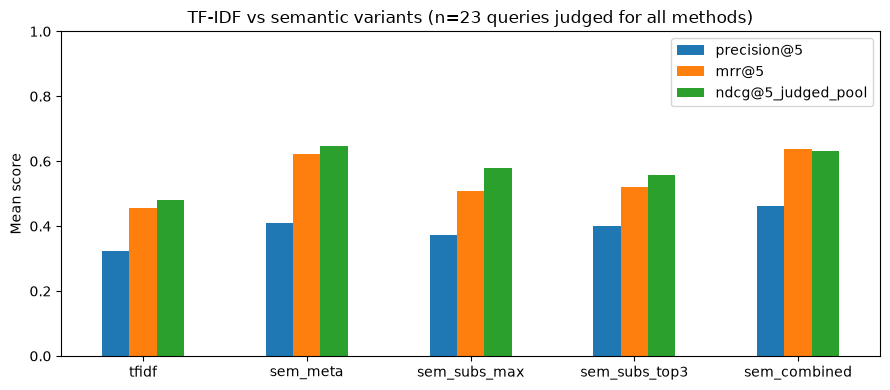

In [11]:
if all_tab is not None:
    import matplotlib.pyplot as plt
    ax = all_tab[METRICS].plot(kind="bar", rot=0, figsize=(9, 4), ylim=(0, 1))
    ax.set_ylabel("Mean score"); ax.set_xlabel("")
    ax.set_title(f"TF-IDF vs semantic variants (n={int(all_tab['n_queries'].iloc[0])} queries judged for all methods)")
    plt.tight_layout(); plt.show()
else:
    print("Chart will appear after the semantic pairs are judged.")

## 9. Failure candidates and saved evidence

Queries where the main semantic variant has **no relevant movie in the top 5**, with the matched subtitle passage.
These are prompts for manual error analysis, not proof of why a query failed.

In [12]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
per_query.to_csv(OUTPUT_DIR / "comparison_per_query.csv", index=False, encoding="utf-8-sig")
if all_tab is not None:
    all_tab.to_csv(OUTPUT_DIR / "comparison_metrics.csv", encoding="utf-8-sig")
zero = done[(done.method == PRIMARY) & (done[f"precision@{TOP_K}"] == 0)]["query_id"] if len(done) else []
fails = rankings[(rankings.method == PRIMARY) & rankings.query_id.isin(zero)]
fails[["query_id", "query", "rank", "title", "genres", "best_chunk"]].to_csv(OUTPUT_DIR / "semantic_failure_candidates.csv", index=False, encoding="utf-8-sig")
print(f"{len(set(zero))} queries with zero relevant results for {PRIMARY}; saved to semantic_failure_candidates.csv")
display(fails[["query_id", "query", "rank", "title", "best_chunk"]].head(15))

3 queries with zero relevant results for sem_combined; saved to semantic_failure_candidates.csv


,query_id,query,rank,title,best_chunk
455,M11,"An adventurous story full of wonder, exploration and discovery.",1,Ways to Live Forever,me any more chemotherapy. My wish is to go up down-escalators. Doing more school work then? No actually I'm writing ...
456,M11,"An adventurous story full of wonder, exploration and discovery.",2,A Short Story,I am I look for him through the earth and sky I don't know who I am What is this world of illusions! Which one is me...
457,M11,"An adventurous story full of wonder, exploration and discovery.",3,Guardian of the Frontier,"life. Ah, you're still so young... you mustn't worry about things like that. That's just what my father says. It dri..."
458,M11,"An adventurous story full of wonder, exploration and discovery.",4,Iceberg Slim: Portrait of a Pimp,"comes what seems to this white cat And then, iceberg then proceeds to tell you this story, But the story is told fro..."
459,M11,"An adventurous story full of wonder, exploration and discovery.",5,All We Ever Wanted,"things. People suddenly saw us as a director and no longer as an animator. I did everything myself then, together wi..."
475,M15,"A movie with the vibe of an old, forgotten seaside town.",1,The Town That Dreaded Sundown,"booming. And people around Texarkana generally were optimistic about the future. It was Sunday, March 3, 1946, the b..."
476,M15,"A movie with the vibe of an old, forgotten seaside town.",2,Bhoot,Presented by cinema service executive producer kang woo-suk cha seung-won jang seo-hee directed by kim sang-jin ghos...
477,M15,"A movie with the vibe of an old, forgotten seaside town.",3,Hum Kaun Hai,"nothing nearby. You'll find here only drifting spirits which you have accepted as your life. But mate, this is not l..."
478,M15,"A movie with the vibe of an old, forgotten seaside town.",4,The Night Strangler,"1965, cleaning up no less than ten tons of debris down here so that people like you wouldn't break your necks walkin..."
479,M15,"A movie with the vibe of an old, forgotten seaside town.",5,High Society,immense world. It's out of your way. It's fine. It's not very far. There it is. I'm going back to Paris tomorrow. By...
